# 04 — Standardization and Scaling Demo

## Task 1: binary classification — synthetic Alzheimer dataset

This notebook demonstrates several common numerical scaling strategies after preprocessing, EDA, and feature engineering.

It is intentionally a **simple educational demo**. It does not build a machine-learning pipeline and it does not train a predictive model. The goal is to make the transformation itself visible before a later notebook combines all preparation steps end to end.

## Learning objectives

After completing this notebook, students should be able to:

- identify which columns should and should not be scaled;
- create the train/test split before fitting a scaler;
- distinguish `fit_transform()` from `transform()`;
- apply StandardScaler, MinMaxScaler, RobustScaler, and MaxAbsScaler;
- verify the numerical properties of each transformation;
- understand why the test set does not have to reproduce the training statistics;
- keep binary categorical indicators and the classification label unchanged;
- distinguish simple scaling from distribution-shaping transformations.

## 1. Scope and leakage rule

The feature-engineering notebook created the analytical feature table used here.

A scaler learns numerical parameters. Therefore, even in a simple demonstration, we follow the correct order:

```text
engineered dataset
      ↓
train / test split
      ↓
fit scaler on TRAIN numerical predictors
      ↓
transform TRAIN and TEST with the same fitted object
```

The test partition is never used to estimate means, standard deviations, minima, maxima, medians, or quantiles.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    PowerTransformer,
    QuantileTransformer,
)

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")

## 3. Project paths

In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

FEATURE_DATA_PATH = (
    PROJECT_ROOT / "data" / "synthetic_alzheimer" / "feature_data" / "synthetic_alzheimer_engineered.csv"
)
PREPROCESSING_REPORT_PATH = (
    PROJECT_ROOT / "data" / "synthetic_alzheimer" / "processed_data" / "preprocessing_report.json"
)

print("Project root:", PROJECT_ROOT)
print("Feature data:", FEATURE_DATA_PATH.relative_to(PROJECT_ROOT))

Project root: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
Feature data: data/synthetic_alzheimer/feature_data/synthetic_alzheimer_engineered.csv


## 4. Load the engineered dataset

This notebook expects notebook `03_feature_engineering_and_selection.ipynb` for this task to have been executed first. We reuse the preprocessing report to preserve the semantic roles of the original columns.

In [3]:
if not FEATURE_DATA_PATH.exists():
    raise FileNotFoundError(
        "Engineered feature data are missing. Run 03_feature_engineering_and_selection.ipynb first."
    )
if not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "Preprocessing report is missing. Run 01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(FEATURE_DATA_PATH)
with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = "patient_id"
TARGET_COLUMN = "alzheimer"
CATEGORICAL_COLUMNS = ['sex_female', 'smoker', 'alcohol_risk', 'physical_inactivity', 'hypertension', 'diabetes_type2', 'dyslipidemia', 'cardiovascular_disease', 'stroke_history', 'depression_history', 'traumatic_brain_injury', 'family_history_alzheimer', 'sleep_disorder', 'chronic_kidney_disease', 'hearing_loss', 'asthma', 'allergy_medication', 'allergy_food', 'allergy_environmental']

# Every remaining numeric predictor is treated as a numerical feature.
NUMERICAL_COLUMNS = [
    column for column in df.columns
    if column not in [ID_COLUMN, TARGET_COLUMN, *CATEGORICAL_COLUMNS]
    and pd.api.types.is_numeric_dtype(df[column])
]

print("Shape:", df.shape)
print("Numerical predictors:", len(NUMERICAL_COLUMNS))
print("Categorical indicators:", len(CATEGORICAL_COLUMNS))
print("Target:", TARGET_COLUMN)
display(df.head())

Shape: (1000, 36)
Numerical predictors: 15
Categorical indicators: 19
Target: alzheimer


,patient_id,age,sex_female,height_cm,weight_kg,bmi,waist_cm,hip_cm,waist_hip_ratio,systolic_bp_mmhg,...,asthma,allergy_medication,allergy_food,allergy_environmental,alzheimer,pulse_pressure_mmhg,mean_arterial_pressure_mmhg,waist_height_ratio,cardiometabolic_risk_count,neurobehavioral_risk_count
0,P0001,75,1,158.7,69.5,27.6,116.6,136.3,0.855,137,...,0,0,0,0,1,60,97.000000,0.734720,0,1
1,P0002,50,1,156.5,70.3,28.7,122.1,130.5,0.936,99,...,0,0,0,0,1,21,85.000000,0.780192,1,0
2,P0003,82,0,169.4,76.6,26.7,117.8,118.3,0.996,153,...,0,0,1,0,1,68,107.666667,0.695396,3,1
3,P0004,72,1,165.2,80.8,29.6,110.1,123.4,0.892,121,...,0,0,0,1,1,46,90.333333,0.666465,0,0
4,P0005,64,1,151.0,75.4,33.0,127.2,144.4,0.881,153,...,0,0,0,1,0,79,100.333333,0.842384,0,1


## 5. Split before fitting any scaler

Because this is a binary classification task, the split is stratified by the target. Scaling does not use the label, but the split still occurs first so that all learned transformation parameters are estimated from training observations only.

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df[TARGET_COLUMN],
    random_state=RANDOM_STATE,
)

X_train = train_df[NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS].copy()
X_test = test_df[NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS].copy()
y_train = train_df[TARGET_COLUMN].copy()
y_test = test_df[TARGET_COLUMN].copy()

split_summary = pd.DataFrame({
    "partition": ["train", "test"],
    "n": [len(train_df), len(test_df)],
})
display(split_summary)
print("Training target counts:")
display(y_train.value_counts().rename_axis("class").to_frame("n"))

,partition,n
0,train,800
1,test,200


Training target counts:


,n
class,
0,526
1,274


## 6. Inspect the original numerical scales

Before transforming anything, inspect the training ranges. Large differences in units make the motivation for scaling visible.

In [5]:
raw_scale_summary = X_train[NUMERICAL_COLUMNS].agg(
    ["mean", "std", "min", "median", "max"]
).T
raw_scale_summary["range"] = raw_scale_summary["max"] - raw_scale_summary["min"]
raw_scale_summary = raw_scale_summary.sort_values("range", ascending=False)
display(raw_scale_summary.round(3))

,mean,std,min,median,max,range
pulse_pressure_mmhg,50.946,14.686,8.000,51.000,94.000,86.000
weight_kg,74.077,13.579,45.000,73.000,128.700,83.700
systolic_bp_mmhg,130.681,14.155,90.000,131.000,173.000,83.000
heart_rate_bpm,71.608,8.128,48.000,72.000,110.000,62.000
age,68.685,11.061,40.000,69.000,95.000,55.000
hip_cm,127.520,10.099,92.900,127.600,145.000,52.100
diastolic_bp_mmhg,79.735,8.376,56.000,80.000,107.000,51.000
mean_arterial_pressure_mmhg,96.717,8.101,70.333,96.667,120.667,50.333
height_cm,165.465,8.215,145.000,165.250,195.000,50.000
waist_cm,117.996,9.136,88.900,118.100,135.000,46.100


# Part I — StandardScaler

## 7. Standardize continuous numerical predictors

`StandardScaler` learns one mean and standard deviation per numerical feature from **TRAIN**. Binary categorical indicators are deliberately left as `0/1`.

In [6]:
standard_scaler = StandardScaler()

X_train_standard = X_train.copy()
X_test_standard = X_test.copy()

X_train_standard[NUMERICAL_COLUMNS] = standard_scaler.fit_transform(
    X_train[NUMERICAL_COLUMNS]
)
X_test_standard[NUMERICAL_COLUMNS] = standard_scaler.transform(
    X_test[NUMERICAL_COLUMNS]
)

standard_check = pd.DataFrame({
    "train_mean": X_train_standard[NUMERICAL_COLUMNS].mean(),
    "train_std_ddof0": X_train_standard[NUMERICAL_COLUMNS].std(ddof=0),
    "test_mean": X_test_standard[NUMERICAL_COLUMNS].mean(),
    "test_std_ddof0": X_test_standard[NUMERICAL_COLUMNS].std(ddof=0),
})

display(standard_check.round(3))

,train_mean,train_std_ddof0,test_mean,test_std_ddof0
age,-0.0,1.0,0.047,0.948
height_cm,-0.0,1.0,0.013,0.975
weight_kg,0.0,1.0,0.045,1.066
bmi,-0.0,1.0,0.045,1.098
waist_cm,-0.0,1.0,0.027,1.050
hip_cm,-0.0,1.0,-0.019,0.987
waist_hip_ratio,0.0,1.0,0.079,1.022
systolic_bp_mmhg,-0.0,1.0,0.046,0.938
diastolic_bp_mmhg,0.0,1.0,-0.149,1.054
heart_rate_bpm,-0.0,1.0,0.005,1.004


### Interpretation

The training means should be approximately zero and training standard deviations approximately one because those statistics defined the transformation.

The **test means and standard deviations should not be forced to zero and one**. Test data are transformed using the training coordinate system.

## 8. Confirm that categorical indicators and the label were not changed

In [7]:
for column in CATEGORICAL_COLUMNS:
    assert X_train_standard[column].equals(X_train[column])
    assert X_test_standard[column].equals(X_test[column])

assert y_train.equals(train_df[TARGET_COLUMN])
assert y_test.equals(test_df[TARGET_COLUMN])

print("PASS — categorical indicators remain unchanged.")
print("PASS — classification labels remain unchanged.")

PASS — categorical indicators remain unchanged.
PASS — classification labels remain unchanged.


## 9. Visualize selected standardized features by class

Scaling is independent of the class label. We use the label only for visualization after the transformation.

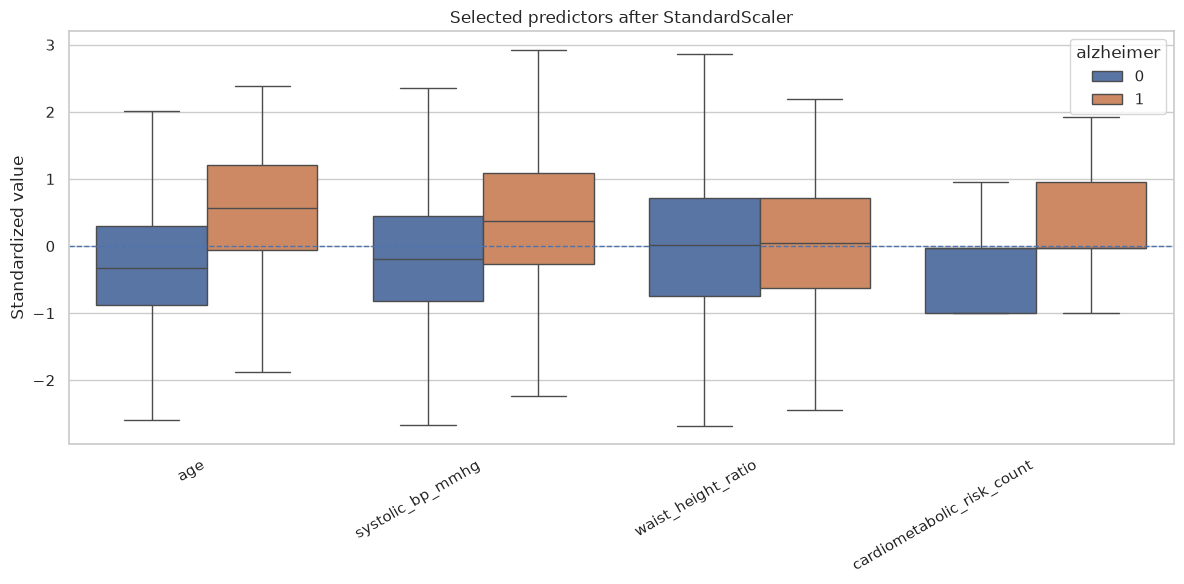

In [8]:
REPRESENTATIVE_FEATURES = ['age', 'systolic_bp_mmhg', 'waist_height_ratio', 'cardiometabolic_risk_count']

plot_df = X_train_standard[REPRESENTATIVE_FEATURES].copy()
plot_df[TARGET_COLUMN] = y_train.values
plot_long = plot_df.melt(
    id_vars=TARGET_COLUMN,
    value_vars=REPRESENTATIVE_FEATURES,
    var_name="feature",
    value_name="standardized_value",
)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=plot_long,
    x="feature",
    y="standardized_value",
    hue=TARGET_COLUMN,
    showfliers=False,
)
plt.axhline(0, linewidth=1, linestyle="--")
plt.title("Selected predictors after StandardScaler")
plt.xlabel("")
plt.ylabel("Standardized value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Part II — Compare common feature-wise scalers

## 10. MinMaxScaler, RobustScaler, and MaxAbsScaler

We now fit several alternative transformations on the same training numerical matrix. This is a comparison of representations, not a search for a universally best scaler.

In [9]:
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
}

scaled_train = {}
scaled_test = {}

for name, scaler in scalers.items():
    scaled_train[name] = pd.DataFrame(
        scaler.fit_transform(X_train[NUMERICAL_COLUMNS]),
        columns=NUMERICAL_COLUMNS,
        index=X_train.index,
    )
    scaled_test[name] = pd.DataFrame(
        scaler.transform(X_test[NUMERICAL_COLUMNS]),
        columns=NUMERICAL_COLUMNS,
        index=X_test.index,
    )

print("Created scaled TRAIN and TEST representations for:")
print(list(scalers))

Created scaled TRAIN and TEST representations for:
['StandardScaler', 'MinMaxScaler', 'RobustScaler', 'MaxAbsScaler']


## 11. Compare one representative feature numerically

The table below makes the different definitions visible. The same observations are represented in four different coordinate systems.

In [10]:
def summarize_transformation(name, train_values, test_values):
    train_values = np.asarray(train_values, dtype=float).ravel()
    test_values = np.asarray(test_values, dtype=float).ravel()
    q1, q3 = np.quantile(train_values, [0.25, 0.75])
    return {
        "method": name,
        "train_mean": train_values.mean(),
        "train_std_ddof0": train_values.std(ddof=0),
        "train_median": np.median(train_values),
        "train_iqr": q3 - q1,
        "train_min": train_values.min(),
        "train_max": train_values.max(),
        "test_min": test_values.min(),
        "test_max": test_values.max(),
    }

comparison_feature = "systolic_bp_mmhg"
rows = []

rows.append(
    summarize_transformation(
        "Raw",
        X_train[comparison_feature],
        X_test[comparison_feature],
    )
)

for name in scalers:
    rows.append(
        summarize_transformation(
            name,
            scaled_train[name][comparison_feature],
            scaled_test[name][comparison_feature],
        )
    )

comparison_table = pd.DataFrame(rows).set_index("method")
display(comparison_table.round(3))

,train_mean,train_std_ddof0,train_median,train_iqr,train_min,train_max,test_min,test_max
method,,,,,,,,
Raw,130.681,14.146,131.000,20.000,90.000,173.000,99.000,172.000
StandardScaler,-0.000,1.000,0.023,1.414,-2.876,2.992,-2.240,2.921
MinMaxScaler,0.490,0.170,0.494,0.241,0.000,1.000,0.108,0.988
RobustScaler,-0.016,0.707,0.000,1.000,-2.050,2.100,-1.600,2.050
MaxAbsScaler,0.755,0.082,0.757,0.116,0.520,1.000,0.572,0.994


## 12. Compare the transformed distribution

Linear scalers preserve ordering. They mainly change location and numerical scale. The faceted visualization uses independent x-axes because the transformed units are intentionally different.

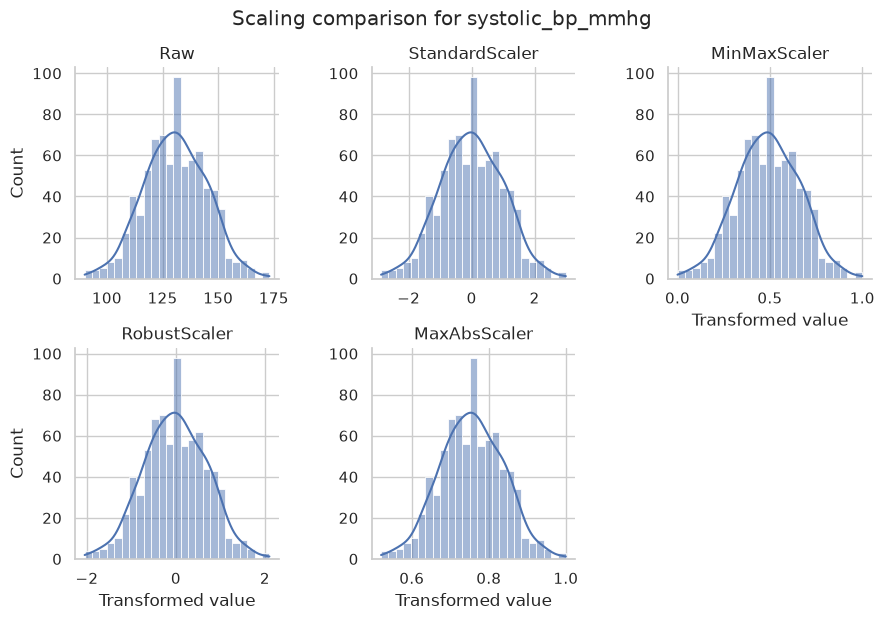

In [11]:
frames = [
    pd.DataFrame({
        "value": X_train[comparison_feature].to_numpy(),
        "method": "Raw",
    })
]
for name in scalers:
    frames.append(pd.DataFrame({
        "value": scaled_train[name][comparison_feature].to_numpy(),
        "method": name,
    }))

comparison_long = pd.concat(frames, ignore_index=True)

g = sns.FacetGrid(
    comparison_long,
    col="method",
    col_wrap=3,
    sharex=False,
    sharey=False,
    height=3.0,
)
g.map_dataframe(sns.histplot, x="value", kde=True, bins=25)
g.set_axis_labels("Transformed value", "Count")
g.set_titles("{col_name}")
g.figure.suptitle(f"Scaling comparison for {comparison_feature}", y=1.03)
plt.show()

## 13. Min-Max test values may exceed the training interval

`MinMaxScaler` guarantees the requested range for the observations used to fit it. A future observation outside the training minimum or maximum can legitimately produce a transformed value below 0 or above 1.

In [12]:
minmax_test = scaled_test["MinMaxScaler"]
outside = ((minmax_test < 0) | (minmax_test > 1)).sum()

minmax_check = pd.DataFrame({
    "test_below_0": (minmax_test < 0).sum(),
    "test_above_1": (minmax_test > 1).sum(),
    "test_outside_training_range": outside,
})
display(minmax_check[minmax_check.sum(axis=1) > 0])

if outside.sum() == 0:
    print("No test observation falls outside the training min/max in this split.")
else:
    print("Some test observations lie outside the training min/max; this is valid behaviour.")

,test_below_0,test_above_1,test_outside_training_range
bmi,0,2,2
hip_cm,0,12,12
pulse_pressure_mmhg,1,1,2


Some test observations lie outside the training min/max; this is valid behaviour.


# Part III — Distribution-shaping transformations

## 14. PowerTransformer and QuantileTransformer

These methods do more than change units. They modify the marginal distribution shape. They should therefore be considered separate modelling choices, not interchangeable synonyms for standardization.

In [13]:
shape_feature = "cardiometabolic_risk_count"

power = PowerTransformer(method="yeo-johnson", standardize=True)
quantile = QuantileTransformer(
    n_quantiles=min(200, len(X_train)),
    output_distribution="normal",
    random_state=RANDOM_STATE,
)

raw_train = X_train[[shape_feature]].to_numpy()
power_train = power.fit_transform(raw_train).ravel()
quantile_train = quantile.fit_transform(raw_train).ravel()

shape_summary = pd.DataFrame({
    "representation": ["Raw", "Yeo-Johnson + standardize", "Quantile -> normal"],
    "mean": [raw_train.mean(), power_train.mean(), quantile_train.mean()],
    "std": [raw_train.std(ddof=0), power_train.std(ddof=0), quantile_train.std(ddof=0)],
    "skewness": [
        pd.Series(raw_train.ravel()).skew(),
        pd.Series(power_train).skew(),
        pd.Series(quantile_train).skew(),
    ],
})
display(shape_summary.round(3))

,representation,mean,std,skewness
0,Raw,1.022,1.031,0.944
1,Yeo-Johnson + standardize,-0.000,1.000,0.038
2,Quantile -> normal,-1.563,2.846,-0.423


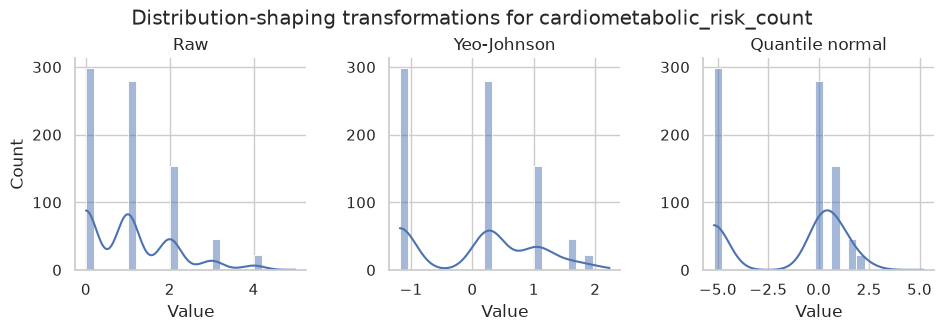

In [14]:
shape_long = pd.concat([
    pd.DataFrame({"value": raw_train.ravel(), "representation": "Raw"}),
    pd.DataFrame({"value": power_train, "representation": "Yeo-Johnson"}),
    pd.DataFrame({"value": quantile_train, "representation": "Quantile normal"}),
], ignore_index=True)

g = sns.FacetGrid(
    shape_long,
    col="representation",
    sharex=False,
    sharey=False,
    height=3.2,
)
g.map_dataframe(sns.histplot, x="value", kde=True, bins=25)
g.set_axis_labels("Value", "Count")
g.set_titles("{col_name}")
g.figure.suptitle(f"Distribution-shaping transformations for {shape_feature}", y=1.03)
plt.show()

# Part IV — What this demo does not do

## 15. Deliberate stopping point

This notebook does **not**:

- choose a final scaler for every model;
- save a single “final scaled dataset”;
- fit an ML model;
- perform cross-validation;
- combine scaling with encoding, feature selection, or model fitting in a pipeline.

Those operations belong to the later end-to-end preparation and modelling demonstrations.

For now, the important lesson is that a scaler is a **learned transformation** and its parameters must come from training data only.

## 16. Take-home summary

For this classification task:

```text
continuous numerical predictors -> eligible for scaling
binary categorical indicators   -> kept as 0/1 in this demo
identifier                      -> excluded
classification label            -> never standardized
```

`StandardScaler` is a strong default for many later scale-sensitive models. `RobustScaler` is useful when legitimate extreme values strongly influence mean and variance. `MinMaxScaler` provides a bounded training representation, while `MaxAbsScaler` rescales without centering. Distribution-shaping methods such as Yeo-Johnson and quantile mapping answer a different question and should be used deliberately.